In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

file_path = Path(
    "../05_Clean_Data/marketing_data_clean.csv"
)

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (2240, 40)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country,Total_Purchases,Deal_Purchase_Issue,Total_Spending,Zero_Purchase_Spending_Issue,Has_Data_Quality_Issue,Data_Quality_Status,Income_Imputed,Education_Standardized,Marital_Status_Group,Customer_Age_Estimated,Age_Group,Income_Group
0,1826,1970,Graduation,Divorced,84835.0,0,0,2014-06-16,0,189,104,379,111,189,218,1,4,4,6,1,0,0,0,0,0,1,0,Spain,14,0,1190,0,0,No Flagged Issue,84835.0,Graduate,Divorced,44,35-44,High Income
1,1,1961,Graduation,Single,57091.0,0,0,2014-06-15,0,464,5,64,7,0,37,1,7,3,7,5,0,0,0,0,1,1,0,Canada,17,0,577,0,0,No Flagged Issue,57091.0,Graduate,Single,53,45-54,Upper-Middle Income
2,10476,1958,Graduation,Married,67267.0,0,1,2014-05-13,0,134,11,59,15,2,30,1,3,2,5,2,0,0,0,0,0,0,0,USA,10,0,251,0,0,No Flagged Issue,67267.0,Graduate,Married,56,55-64,Upper-Middle Income
3,1386,1967,Graduation,Together,32474.0,1,1,2014-05-11,0,10,0,1,0,0,0,1,1,0,2,7,0,0,0,0,0,0,0,Australia,3,0,11,0,0,No Flagged Issue,32474.0,Graduate,Partnered,47,45-54,Low Income
4,5371,1989,Graduation,Single,21474.0,1,0,2014-04-08,0,6,16,24,11,0,34,2,3,1,2,7,1,0,0,0,0,1,0,Spain,6,0,91,0,0,No Flagged Issue,21474.0,Graduate,Single,25,25-34,Low Income


In [2]:
rfm_columns = [
    "ID",
    "Recency",
    "Total_Purchases",
    "Total_Spending",
    "Has_Data_Quality_Issue"
]

missing_columns = [
    col for col in rfm_columns
    if col not in df.columns
]

print("Missing Columns:", missing_columns)

Missing Columns: []


In [3]:
rfm = df[
    [
        "ID",
        "Recency",
        "Total_Purchases",
        "Total_Spending",
        "Has_Data_Quality_Issue"
    ]
].copy()

rfm = rfm.rename(columns={
    "Total_Purchases": "Frequency",
    "Total_Spending": "Monetary"
})

display(rfm.head())

,ID,Recency,Frequency,Monetary,Has_Data_Quality_Issue
0,1826,0,14,1190,0
1,1,0,17,577,0
2,10476,0,10,251,0
3,1386,0,3,11,0
4,5371,0,6,91,0


In [4]:
print("Total Rows:", len(rfm))

print(
    "Unique Customers:",
    rfm["ID"].nunique()
)

print(
    "Duplicate Customer IDs:",
    rfm["ID"].duplicated().sum()
)

Total Rows: 2240
Unique Customers: 2240
Duplicate Customer IDs: 0


In [5]:
rfm_valid = rfm[
    (rfm["Has_Data_Quality_Issue"] == 0) &
    (rfm["Recency"].notna()) &
    (rfm["Frequency"].notna()) &
    (rfm["Monetary"].notna()) &
    (rfm["Recency"] >= 0) &
    (rfm["Frequency"] > 0) &
    (rfm["Monetary"] >= 0)
].copy()

print("Total Customers:", len(rfm))

print("RFM Eligible Customers:", len(rfm_valid))

Total Customers: 2240
RFM Eligible Customers: 2233


In [6]:
display(
    rfm_valid[
        ["Recency", "Frequency", "Monetary"]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
Recency,2233.0,49.085087,28.976738,0.0,24.0,49.0,74.0,99.0
Frequency,2233.0,12.575907,7.183444,1.0,6.0,12.0,18.0,32.0
Monetary,2233.0,607.598746,602.322676,8.0,69.0,397.0,1048.0,2525.0


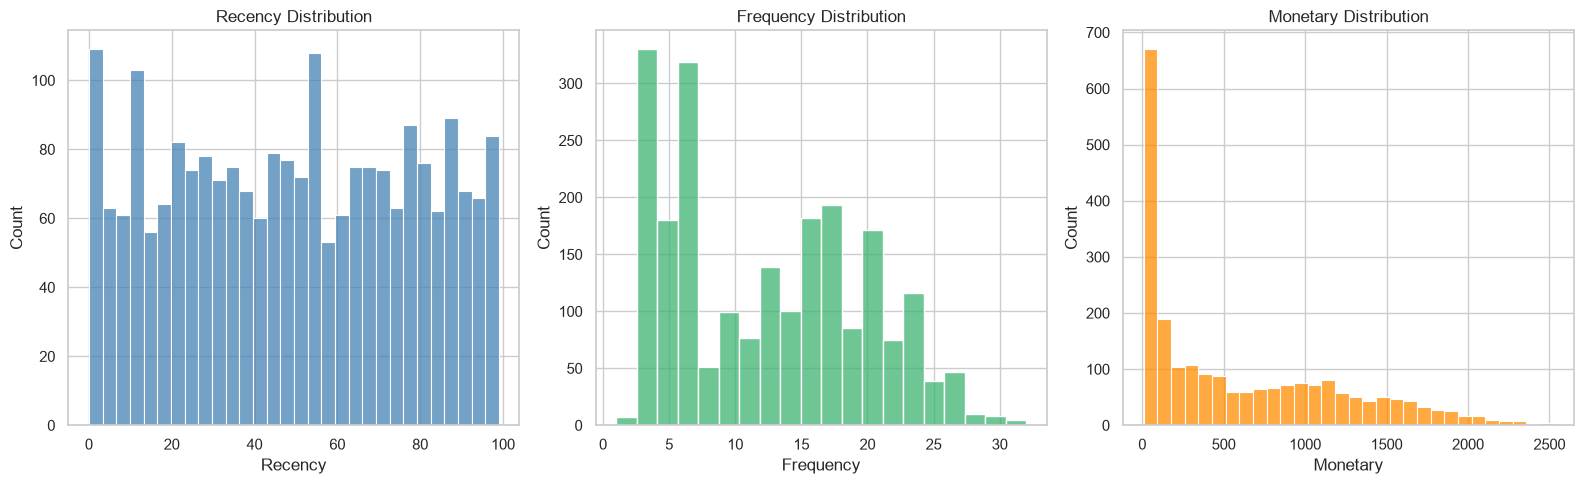

In [7]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

sns.histplot(
    rfm_valid["Recency"],
    bins=30,
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Recency Distribution")

sns.histplot(
    rfm_valid["Frequency"],
    bins=20,
    ax=axes[1],
    color="mediumseagreen"
)

axes[1].set_title("Frequency Distribution")

sns.histplot(
    rfm_valid["Monetary"],
    bins=30,
    ax=axes[2],
    color="darkorange"
)

axes[2].set_title("Monetary Distribution")

plt.tight_layout()
plt.show()

In [8]:
rfm_valid["R_Score"] = pd.cut(
    rfm_valid["Recency"].rank(
        method="average",
        ascending=False,
        pct=True
    ),
    bins=[0, .2, .4, .6, .8, 1],
    labels=[5, 4, 3, 2, 1],
    include_lowest=True
).astype(int)

In [9]:
rfm_valid["F_Score"] = pd.cut(
    rfm_valid["Frequency"].rank(
        method="average",
        ascending=True,
        pct=True
    ),
    bins=[0, .2, .4, .6, .8, 1],
    labels=[1, 2, 3, 4, 5],
    include_lowest=True
).astype(int)

In [10]:
rfm_valid["M_Score"] = pd.cut(
    rfm_valid["Monetary"].rank(
        method="average",
        ascending=True,
        pct=True
    ),
    bins=[0, .2, .4, .6, .8, 1],
    labels=[1, 2, 3, 4, 5],
    include_lowest=True
).astype(int)

In [11]:
rfm_valid["RFM_Code"] = (
    rfm_valid["R_Score"].astype(str)
    + rfm_valid["F_Score"].astype(str)
    + rfm_valid["M_Score"].astype(str)
)

In [12]:
rfm_valid["RFM_Total_Score"] = (
    rfm_valid["R_Score"]
    + rfm_valid["F_Score"]
    + rfm_valid["M_Score"]
)

In [13]:
display(
    rfm_valid[
        [
            "ID",
            "Recency",
            "Frequency",
            "Monetary",
            "R_Score",
            "F_Score",
            "M_Score",
            "RFM_Code",
            "RFM_Total_Score"
        ]
    ].head(15)
)

,ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Code,RFM_Total_Score
0,1826,0,14,1190,1,3,5,135,9
1,1,0,17,577,1,4,3,143,8
2,10476,0,10,251,1,3,3,133,7
3,1386,0,3,11,1,1,1,111,3
4,5371,0,6,91,1,2,2,122,5
5,7348,0,16,1192,1,4,5,145,10
6,4073,0,27,1215,1,5,5,155,11
7,1991,0,6,96,1,2,2,122,5
8,4047,0,17,544,1,4,3,143,8
9,9477,0,17,544,1,4,3,143,8


In [15]:
conditions = [
    (
        (rfm_valid["R_Score"] >= 4) &
        (rfm_valid["F_Score"] >= 4) &
        (rfm_valid["M_Score"] >= 4)
    ),

    (
        (rfm_valid["R_Score"] <= 2) &
        (
            (rfm_valid["F_Score"] >= 4) |
            (rfm_valid["M_Score"] >= 4)
        )
    ),

    (
        (rfm_valid["R_Score"] >= 3) &
        (rfm_valid["F_Score"] >= 4)
    ),

    (
        (rfm_valid["R_Score"] >= 4) &
        (rfm_valid["F_Score"] <= 3)
    )
]

choices = [
    "Champions",
    "At Risk",
    "Loyal Customers",
    "Potential Loyalists"
]

rfm_valid["RFM_Segment"] = np.select(
    conditions,
    choices,
    default="Low Engagement"
)

In [16]:
segment_distribution = (
    rfm_valid["RFM_Segment"]
    .value_counts()
    .reset_index()
)

segment_distribution.columns = [
    "RFM_Segment",
    "Customer_Count"
]

segment_distribution["Customer_Share"] = (
    segment_distribution["Customer_Count"]
    / len(rfm_valid)
    * 100
).round(2)

display(segment_distribution)

,RFM_Segment,Customer_Count,Customer_Share
0,Low Engagement,755,33.81
1,Potential Loyalists,517,23.15
2,At Risk,402,18.00
3,Champions,329,14.73
4,Loyal Customers,230,10.30


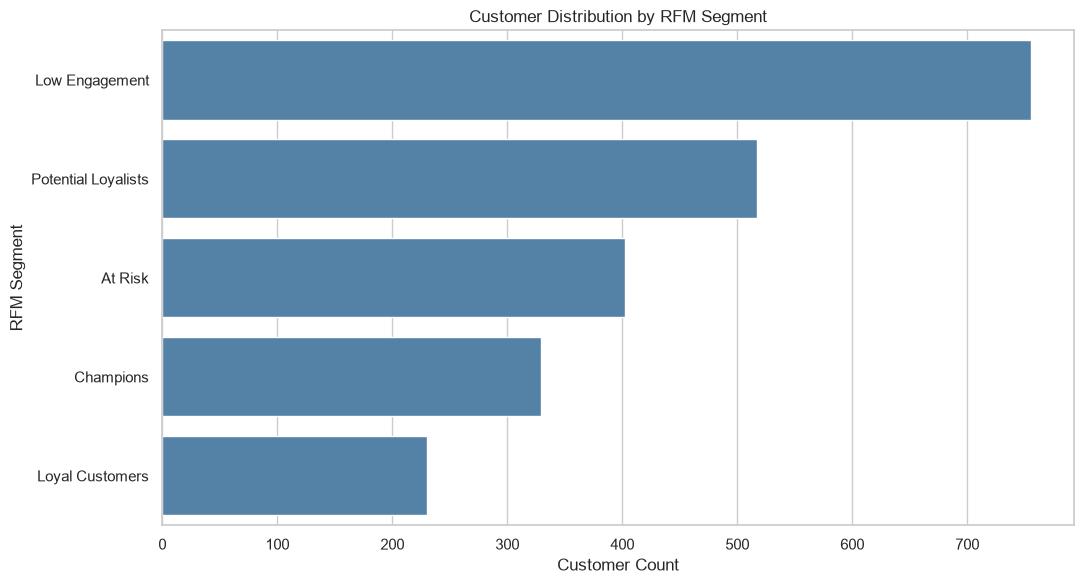

In [17]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=segment_distribution,
    x="Customer_Count",
    y="RFM_Segment",
    color="steelblue"
)

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Customer Count")
plt.ylabel("RFM Segment")

plt.tight_layout()
plt.show()

In [18]:
segment_performance = (
    rfm_valid.groupby("RFM_Segment")
    .agg(
        Total_Customers=("ID", "nunique"),
        Total_Spending=("Monetary", "sum"),
        Avg_Spending=("Monetary", "mean"),
        Avg_Purchases=("Frequency", "mean"),
        Avg_Recency=("Recency", "mean"),
        Avg_RFM_Score=("RFM_Total_Score", "mean")
    )
    .reset_index()
)

segment_performance["Spending_Share"] = (
    segment_performance["Total_Spending"]
    / segment_performance["Total_Spending"].sum()
    * 100
).round(2)

display(
    segment_performance.sort_values(
        "Total_Spending",
        ascending=False
    ).round(2)
)

,RFM_Segment,Total_Customers,Total_Spending,Avg_Spending,Avg_Purchases,Avg_Recency,Avg_RFM_Score,Spending_Share
0,At Risk,402,458950,1141.67,19.41,18.56,10.15,33.83
1,Champions,329,417748,1269.75,20.50,78.79,13.58,30.79
3,Loyal Customers,230,235616,1024.42,19.28,55.09,11.75,17.37
2,Low Engagement,755,125945,166.81,6.99,29.58,5.83,9.28
4,Potential Loyalists,517,118509,229.22,7.40,79.73,8.59,8.73


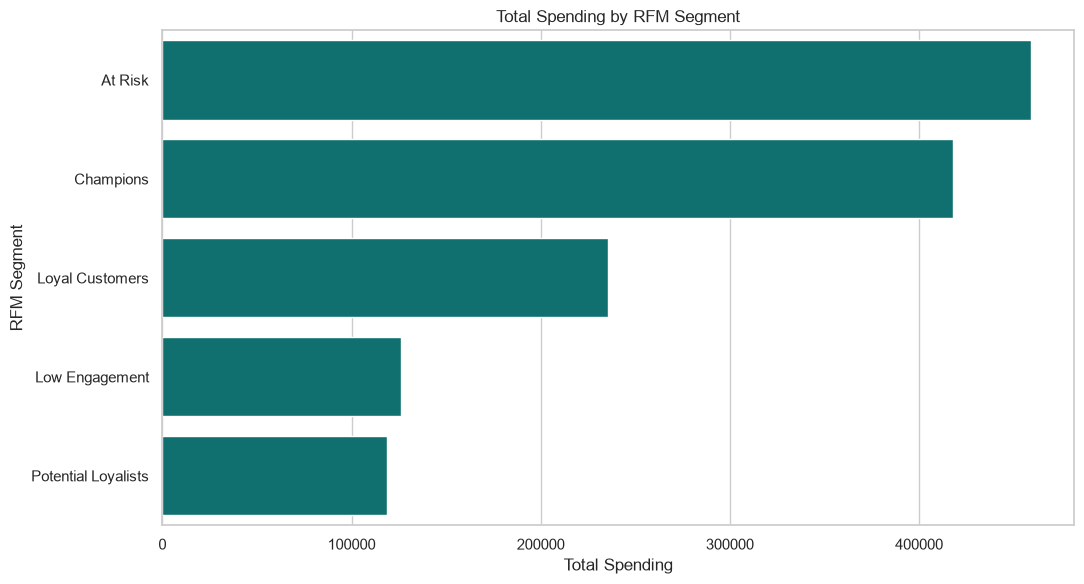

In [19]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=segment_performance.sort_values(
        "Total_Spending",
        ascending=False
    ),
    x="Total_Spending",
    y="RFM_Segment",
    color="teal"
)

plt.title("Total Spending by RFM Segment")
plt.xlabel("Total Spending")
plt.ylabel("RFM Segment")

plt.tight_layout()
plt.show()

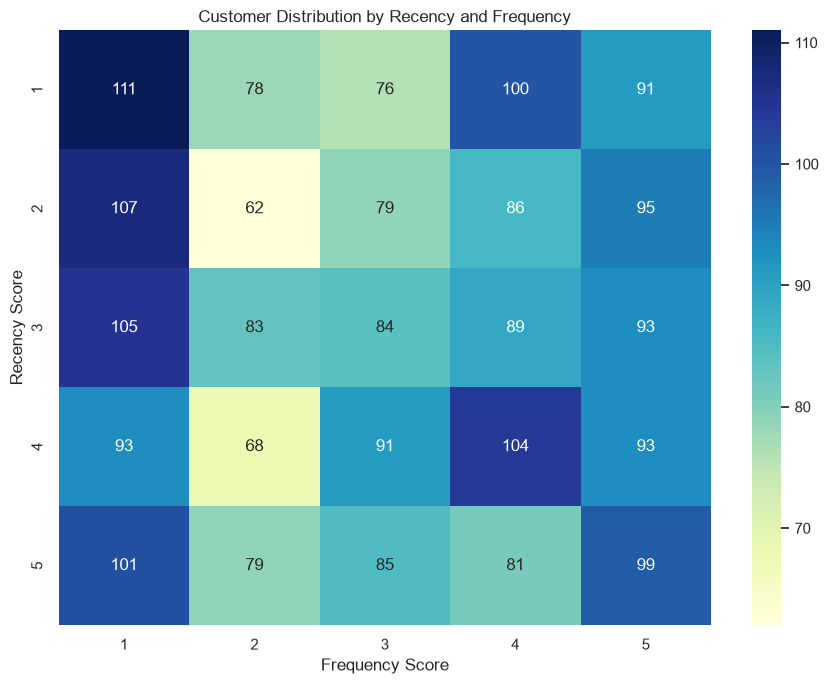

In [20]:
rf_heatmap = pd.crosstab(
    rfm_valid["R_Score"],
    rfm_valid["F_Score"]
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    rf_heatmap,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("Customer Distribution by Recency and Frequency")
plt.xlabel("Frequency Score")
plt.ylabel("Recency Score")

plt.tight_layout()
plt.show()

In [21]:
rfm_valid = rfm_valid.merge(
    df[["ID", "Response"]],
    on="ID",
    how="left",
    validate="one_to_one"
)

In [22]:
rfm_campaign_analysis = (
    rfm_valid.groupby("RFM_Segment")
    .agg(
        Total_Customers=("ID", "nunique"),
        Accepted_Customers=("Response", "sum"),
        Response_Rate=("Response", "mean"),
        Avg_Spending=("Monetary", "mean")
    )
    .reset_index()
)

rfm_campaign_analysis["Response_Rate"] = (
    rfm_campaign_analysis["Response_Rate"] * 100
).round(2)

display(
    rfm_campaign_analysis.sort_values(
        "Response_Rate",
        ascending=False
    )
)

,RFM_Segment,Total_Customers,Accepted_Customers,Response_Rate,Avg_Spending
0,At Risk,402,121,30.10,1141.666667
3,Loyal Customers,230,38,16.52,1024.417391
1,Champions,329,51,15.50,1269.750760
2,Low Engagement,755,101,13.38,166.814570
4,Potential Loyalists,517,23,4.45,229.224371


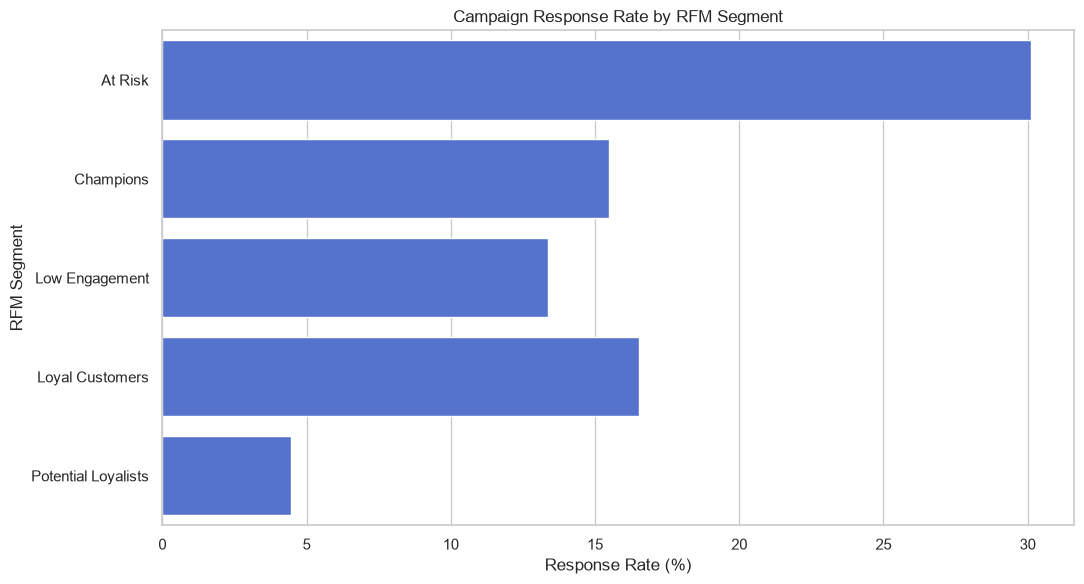

In [23]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=rfm_campaign_analysis,
    x="Response_Rate",
    y="RFM_Segment",
    color="royalblue"
)

plt.title("Campaign Response Rate by RFM Segment")
plt.xlabel("Response Rate (%)")
plt.ylabel("RFM Segment")

plt.tight_layout()
plt.show()

In [24]:
validation_checks = {
    "Duplicate Customers": (
        rfm_valid["ID"].duplicated().sum()
    ),

    "Invalid R Score": (
        ~rfm_valid["R_Score"].between(1, 5)
    ).sum(),

    "Invalid F Score": (
        ~rfm_valid["F_Score"].between(1, 5)
    ).sum(),

    "Invalid M Score": (
        ~rfm_valid["M_Score"].between(1, 5)
    ).sum(),

    "Invalid Total Score": (
        ~rfm_valid["RFM_Total_Score"].between(3, 15)
    ).sum(),

    "Missing RFM Segment": (
        rfm_valid["RFM_Segment"].isna().sum()
    )
}

validation_df = pd.DataFrame(
    validation_checks.items(),
    columns=["Check", "Issue_Count"]
)

display(validation_df)

,Check,Issue_Count
0,Duplicate Customers,0
1,Invalid R Score,0
2,Invalid F Score,0
3,Invalid M Score,0
4,Invalid Total Score,0
5,Missing RFM Segment,0


In [25]:
rfm_features = rfm_valid[
    [
        "ID",
        "R_Score",
        "F_Score",
        "M_Score",
        "RFM_Code",
        "RFM_Total_Score",
        "RFM_Segment"
    ]
].copy()

df_rfm_final = df.merge(
    rfm_features,
    on="ID",
    how="left",
    validate="one_to_one"
)

df_rfm_final["RFM_Segment"] = (
    df_rfm_final["RFM_Segment"]
    .fillna("Needs Review / No Recorded Purchase")
)

In [26]:
print("Original Customers:", df["ID"].nunique())

print(
    "Final RFM Customers:",
    df_rfm_final["ID"].nunique()
)

display(
    df_rfm_final["RFM_Segment"].value_counts()
)

Original Customers: 2240
Final RFM Customers: 2240


RFM_Segment
Low Engagement                         755
Potential Loyalists                    517
At Risk                                402
Champions                              329
Loyal Customers                        230
Needs Review / No Recorded Purchase      7
Name: count, dtype: int64

In [27]:
output_dir = Path("../05_Clean_Data")

output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir / "marketing_data_rfm.csv"
)

df_rfm_final.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("RFM Dataset Exported:", output_path)

RFM Dataset Exported: ..\05_Clean_Data\marketing_data_rfm.csv
